## 6.1梯度累加对训练和结果的影响

### batch_size:8

In [145]:
! python train.py --model_type='bert' \
                    --model_name_or_path='bert-base-cased' \
                    --prepro_data_dir='prepro_data' \
                    --save_name='train_b8'\
                    --batch_size=8

Reading testing data...
Traceback (most recent call last):
  File "/home/shaw/work/NLP/hw4/src/train.py", line 49, in <module>
    con.train(args.model_type, args.model_name_or_path, args.save_name)
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 420, in train
    self.load_test_data()
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 140, in load_test_data
    self.rel2id = json.load(open(os.path.join(self.data_path, 'rel2id.json')))
FileNotFoundError: [Errno 2] No such file or directory: 'prepro_data/rel2id.json'


### batch_size:4 gradient_accumulation_steps:8

In [146]:
! python train.py --model_type='bert' \
                    --model_name_or_path='bert-base-cased' \
                    --prepro_data_dir='prepro_data' \
                    --save_name='train_b4_g8'\
                    --batch_size=4 \
                    --gradient_accumulation_steps=8

Reading testing data...
Traceback (most recent call last):
  File "/home/shaw/work/NLP/hw4/src/train.py", line 49, in <module>
    con.train(args.model_type, args.model_name_or_path, args.save_name)
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 420, in train
    self.load_test_data()
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 140, in load_test_data
    self.rel2id = json.load(open(os.path.join(self.data_path, 'rel2id.json')))
FileNotFoundError: [Errno 2] No such file or directory: 'prepro_data/rel2id.json'


### 小结

In [147]:
import pandas as pd

file_object1 = open("./log/save/train_b8",'r')

df = pd.DataFrame(columns=['epoch','loss'])

lines = open("./log/save/train_b8",'r').read().strip().split('\n')
print(len(lines))
for line in lines:
    if line.startswith('| epoch') and len(line)>=100:
        line = line.lower()
        epoch = line[line.index('| epoch')+8:11]
        epoch = int(epoch)
        
        loss = line[line.index('train loss')+11:62]
        loss = float(loss)
        df.loc[len(df)] =[epoch,loss]
df_b8 =df.groupby('epoch').mean().reset_index()
df_b8

1754


,epoch,loss
0,0.0,0.653080
1,1.0,0.037338
2,2.0,0.024310
3,3.0,0.017019
4,4.0,0.012671
...,...,...
195,195.0,0.000007
196,196.0,0.000008
197,197.0,0.000005
198,198.0,0.000009


In [148]:
file_object1 = open("./log/save/train_b4_g8",'r')

df = pd.DataFrame(columns=['epoch','loss'])

lines = open("./log/save/train_b8",'r').read().strip().split('\n')
print(len(lines))
for line in lines:
    if line.startswith('| epoch') and len(line)>=100:
        line = line.lower()
        epoch = line[line.index('| epoch')+8:11]
        epoch = int(epoch)
        
        loss = line[line.index('train loss')+11:62]
        loss = float(loss)
        df.loc[len(df)] =[epoch,loss]
df_b4_g8 =df.groupby('epoch').mean().reset_index()
df_b4_g8

1754


,epoch,loss
0,0.0,0.653080
1,1.0,0.037338
2,2.0,0.024310
3,3.0,0.017019
4,4.0,0.012671
...,...,...
195,195.0,0.000007
196,196.0,0.000008
197,197.0,0.000005
198,198.0,0.000009


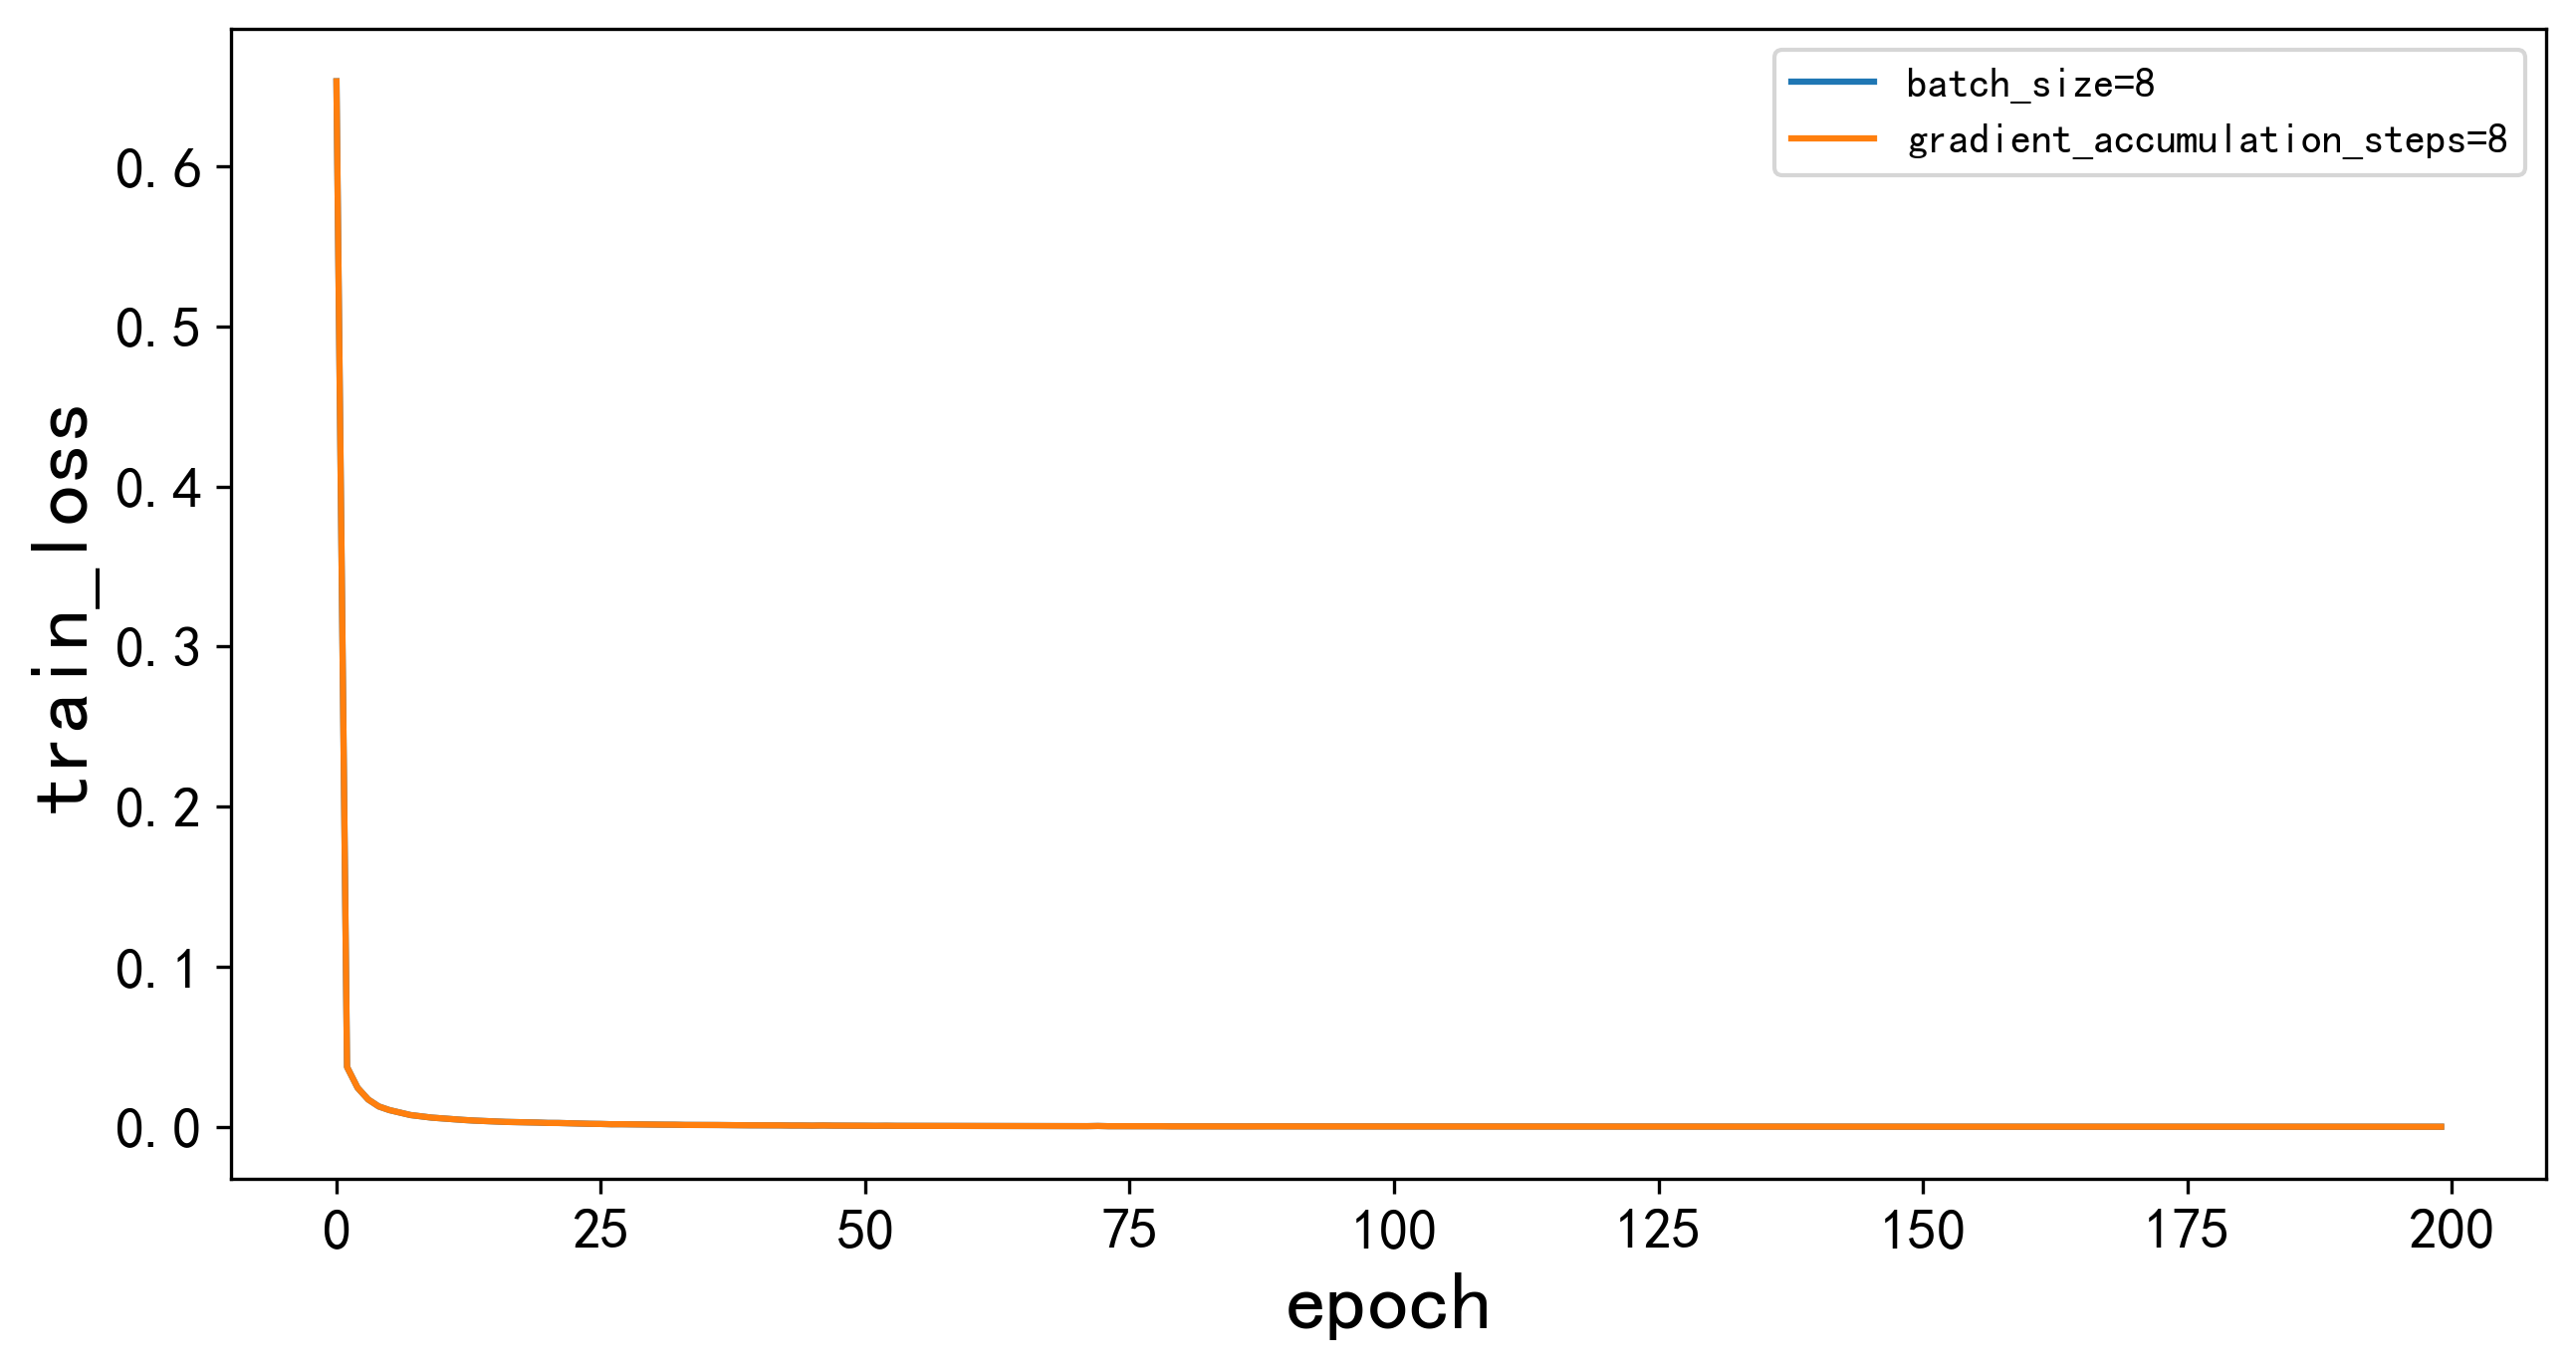

In [149]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(range(len(df_b8['loss'])),df_b8['loss'].values, label='batch_size=8')
plt.plot(range(len(df_b4_g8['loss'])),df_b4_g8['loss'].values, label='gradient_accumulation_steps=8')

plt.xlabel('epoch', fontsize=20, fontweight='bold')
plt.ylabel('train_loss', fontsize=20, fontweight='bold')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

In [150]:
import pandas as pd

lines = open("./log/save/train_b8",'r').read().strip().split('\n')
lines = lines[0:len(lines)-18]
f1_b8 = []
for line in lines:
    if line.startswith('ALL') :
        epoch = line[line.index('F1')+3:line.index('F1')+10]       
        epoch = float(epoch)
        f1_b8.append(epoch)

In [151]:
import pandas as pd

lines = open("./log/save/train_b8",'r').read().strip().split('\n')
lines = lines[0:len(lines)-18]
f1_b4_g8 = []
for line in lines:
    if line.startswith('ALL') :
        epoch = line[line.index('F1')+3:line.index('F1')+10]       
        epoch = float(epoch)
        f1_b4_g8.append(epoch)

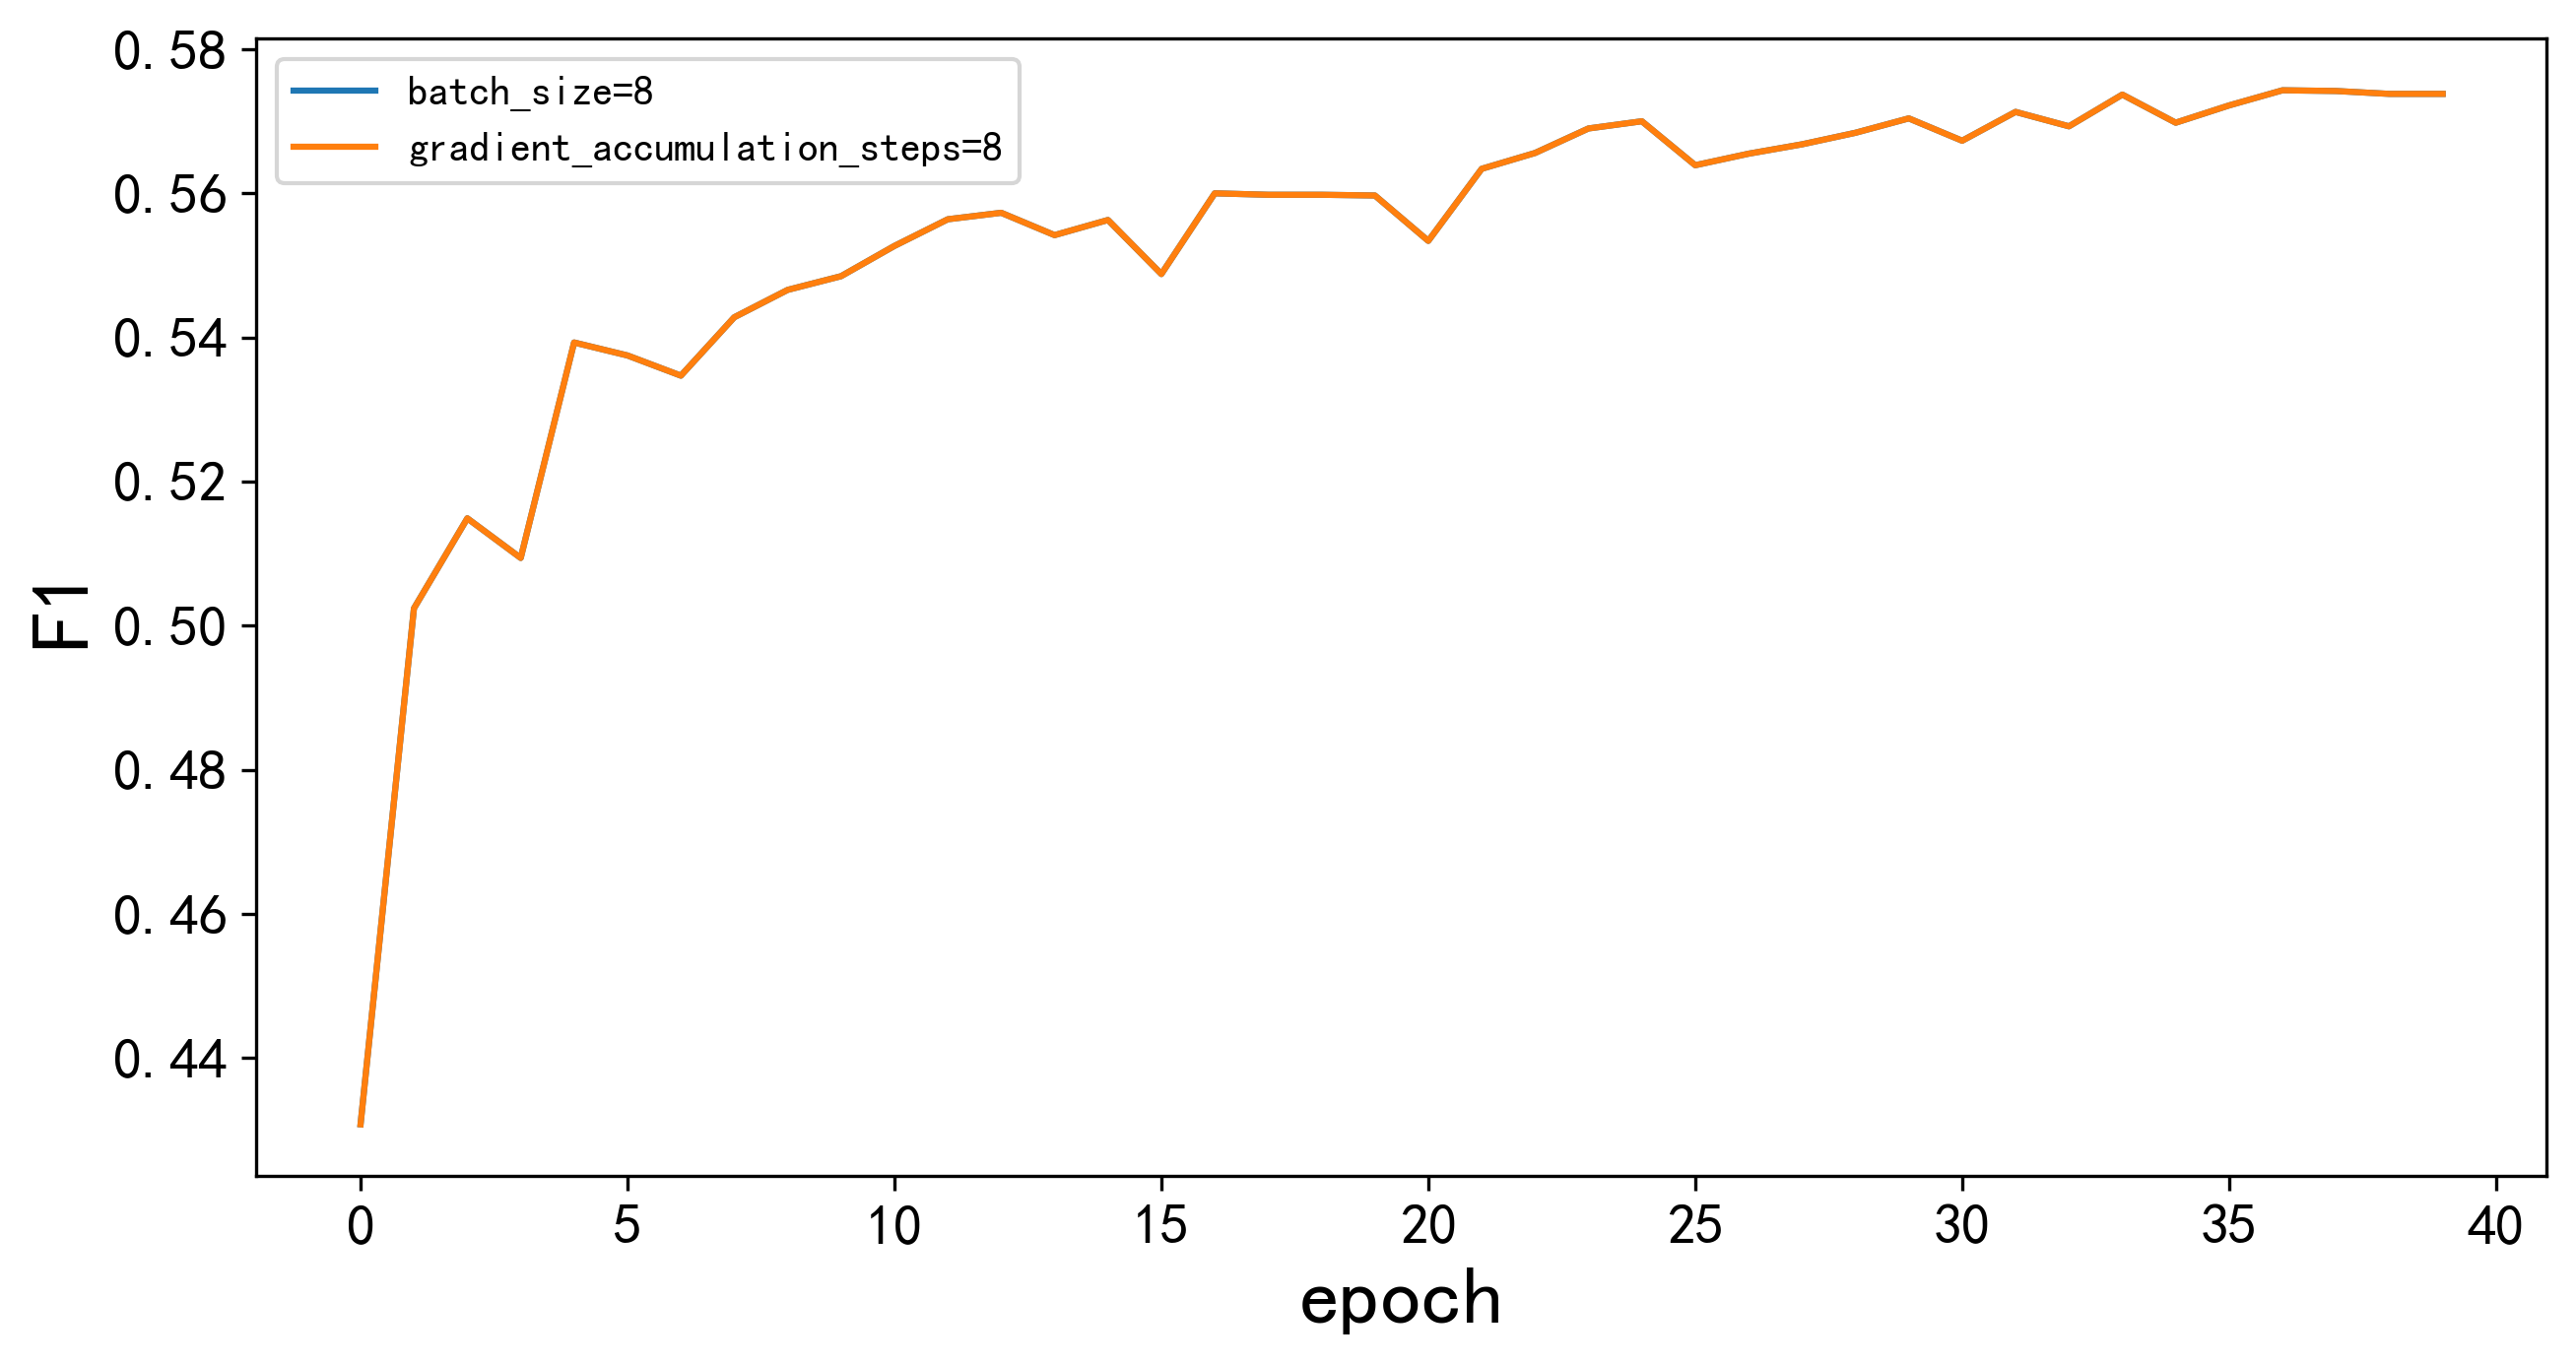

In [152]:
plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(range(len(f1_b8)),f1_b8,  label='batch_size=8')
plt.plot(range(len(f1_b4_g8)),f1_b4_g8, label='gradient_accumulation_steps=8')

plt.xlabel('epoch', fontsize=20, fontweight='bold')
plt.ylabel('F1', fontsize=20, fontweight='bold')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

## 6.2 batch_size对训练和结果的影响

In [153]:
! python train.py --model_type='bert' \
                    --model_name_or_path='bert-base-cased' \
                    --prepro_data_dir='prepro_data' \
                    --save_name='train_b8_g16_lr0001_w001'\
                    --batch_size=8 \
                    --gradient_accumulation_steps=16 \
                    --learning_rate=1e-4 \
                    --weight_decay=0.01 \
                    --logging_steps=25

Reading testing data...
Traceback (most recent call last):
  File "/home/shaw/work/NLP/hw4/src/train.py", line 49, in <module>
    con.train(args.model_type, args.model_name_or_path, args.save_name)
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 420, in train
    self.load_test_data()
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 140, in load_test_data
    self.rel2id = json.load(open(os.path.join(self.data_path, 'rel2id.json')))
FileNotFoundError: [Errno 2] No such file or directory: 'prepro_data/rel2id.json'


## 6.3 学习率对训练和结果的影响

In [154]:
! python train.py --model_type='bert' \
                    --model_name_or_path='bert-base-cased' \
                    --prepro_data_dir='prepro_data' \
                    --save_name='train_b4_g8_lr0001_w001'\
                    --batch_size=4 \
                    --gradient_accumulation_steps=8 \
                    --learning_rate=1e-4 \
                    --weight_decay=0.01 \
                    --logging_steps=100

Reading testing data...
Traceback (most recent call last):
  File "/home/shaw/work/NLP/hw4/src/train.py", line 49, in <module>
    con.train(args.model_type, args.model_name_or_path, args.save_name)
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 420, in train
    self.load_test_data()
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 140, in load_test_data
    self.rel2id = json.load(open(os.path.join(self.data_path, 'rel2id.json')))
FileNotFoundError: [Errno 2] No such file or directory: 'prepro_data/rel2id.json'


In [155]:
! python train.py --model_type='bert' \
                    --model_name_or_path='bert-base-cased' \
                    --prepro_data_dir='prepro_data' \
                    --save_name='train_b4_g8_lr00001_w001'\
                    --batch_size=4 \
                    --gradient_accumulation_steps=8 \
                    --learning_rate=1e-5 \
                    --weight_decay=0.01 \
                    --logging_steps=100

Reading testing data...
Traceback (most recent call last):
  File "/home/shaw/work/NLP/hw4/src/train.py", line 49, in <module>
    con.train(args.model_type, args.model_name_or_path, args.save_name)
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 420, in train
    self.load_test_data()
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 140, in load_test_data
    self.rel2id = json.load(open(os.path.join(self.data_path, 'rel2id.json')))
FileNotFoundError: [Errno 2] No such file or directory: 'prepro_data/rel2id.json'


## 6.4预训练模型对训练和结果的影响-oberta-base

roberta + roberta-base

In [156]:
! python train.py --model_type='roberta' \
                    --model_name_or_path='roberta-base' \
                    --prepro_data_dir='roberta_data' \
                    --save_name='roberta-base_b4_g8_lr00002_w001'\
                    --batch_size=4 \
                    --gradient_accumulation_steps=8 \
                    --learning_rate=2e-5 \
                    --weight_decay=0.01 \
                    --logging_steps=50

Reading testing data...
dev
Finish reading
Some weights of the model checkpoint at roberta-base were not used when initializing RobertaModel: ['lm_head.layer_norm.weight', 'lm_head.dense.weight', 'lm_head.decoder.weight', 'lm_head.bias', 'lm_head.dense.bias', 'lm_head.layer_norm.bias']
- This IS expected if you are initializing RobertaModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or s

### roberta + roberta-base， 300epoch

In [4]:
! python train.py --model_type='roberta' \
                    --model_name_or_path='roberta-base' \
                    --prepro_data_dir='roberta_data' \
                    --save_name='roberta-base_b4_g8_lr00002_w001'\
                    --batch_size=4 \
                    --gradient_accumulation_steps=8 \
                    --learning_rate=2e-5 \
                    --weight_decay=0.01 \
                    --logging_steps=50 \
                    --load_state_form_checkpoint_dir=1 \
                    --num_train_epochs=100

Reading testing data...
dev
Finish reading
Some weights of the model checkpoint at roberta-base were not used when initializing RobertaModel: ['lm_head.layer_norm.bias', 'lm_head.dense.weight', 'lm_head.decoder.weight', 'lm_head.dense.bias', 'lm_head.bias', 'lm_head.layer_norm.weight']
- This IS expected if you are initializing RobertaModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or s

### roberta + roberta-base， hidden_size = 256

In [1]:
! python train.py --model_type='roberta' \
                    --model_name_or_path='roberta-base' \
                    --prepro_data_dir='roberta_data' \
                    --save_name='roberta-base_b4_g8_lr00002_w001_h256'\
                    --batch_size=4 \
                    --gradient_accumulation_steps=8 \
                    --learning_rate=2e-5 \
                    --weight_decay=0.01 \
                    --logging_steps=50 
                    # --num_train_epochs=100

Reading testing data...
dev
Finish reading
Some weights of the model checkpoint at roberta-base were not used when initializing RobertaModel: ['lm_head.decoder.weight', 'lm_head.dense.weight', 'lm_head.dense.bias', 'lm_head.bias', 'lm_head.layer_norm.weight', 'lm_head.layer_norm.bias']
- This IS expected if you are initializing RobertaModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or s

### roberta + roberta-base， hidden_size = 256 ， 300epoch

In [1]:
! python train.py --model_type='roberta' \
                    --model_name_or_path='roberta-base' \
                    --prepro_data_dir='roberta_data' \
                    --save_name='roberta-base_b4_g8_lr00002_w001_h256'\
                    --batch_size=4 \
                    --gradient_accumulation_steps=8 \
                    --learning_rate=1e-5 \
                    --weight_decay=0.01 \
                    --logging_steps=50 \
                    --load_state_form_checkpoint_dir=1 \
                    --devset_sample_trainingset_rate=0 \
                    --num_train_epochs=200

Traceback (most recent call last):
  File "/home/shaw/work/NLP/hw4/src/train.py", line 47, in <module>
    con = config.Config(args)
  File "/home/shaw/work/NLP/hw4/src/config/Config.py", line 138, in __init__
    self.devset_sample_trainingset_rate =args.devset_sample_trainingset_rate
AttributeError: 'Namespace' object has no attribute 'devset_sample_trainingset_rate'
